# Mini-Courier Planner

**Capstone prototype | Python | Algorithms: Sorting, 0/1 Knapsack DP, Dijkstra, Nearest-Neighbor TSP Approximation**

This notebook follows the assignment requirements: parcel prioritization, capacity-constrained packing, shortest-path calculation, approximate overall route planning, correctness checks, runtime comparisons, and a chart. It uses only the supplied sample CSV files and locally generated benchmark data.

**Rules used in this prototype:** lower numeric priority means higher priority; vehicle capacity is 12 weight units; route edges are undirected and have positive weights; the courier begins and finishes at `Depot`.

In [1]:
from pathlib import Path
import heapq
import random
import statistics
import time

import matplotlib.pyplot as plt
import pandas as pd

# Run this notebook from the project root directory.
ROOT = Path.cwd()
DATA_DIR = ROOT / "datasets"
IMAGE_DIR = ROOT / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

PARCELS_FILE = DATA_DIR / "parcels.csv"
ROUTES_FILE = DATA_DIR / "routes.csv"
if not PARCELS_FILE.exists() or not ROUTES_FILE.exists():
    raise FileNotFoundError(
        "Dataset files were not found. Open this notebook from the mini-courier-planner project folder."
    )

parcels = pd.read_csv(PARCELS_FILE)
route_edges = pd.read_csv(ROUTES_FILE)
VEHICLE_CAPACITY = 12
DEPOT = "Depot"

required_parcel_columns = {"parcel_id", "destination", "weight", "value", "priority", "deadline"}
required_route_columns = {"source", "target", "distance"}
if not required_parcel_columns.issubset(parcels.columns):
    raise ValueError(f"Parcel dataset must contain: {sorted(required_parcel_columns)}")
if not required_route_columns.issubset(route_edges.columns):
    raise ValueError(f"Route dataset must contain: {sorted(required_route_columns)}")
if (parcels["weight"] <= 0).any() or (parcels["value"] < 0).any():
    raise ValueError("Parcel weights must be positive and parcel values must be non-negative.")
if (route_edges["distance"] <= 0).any():
    raise ValueError("All road distances must be positive.")

print(f"Loaded {len(parcels)} parcels and {len(route_edges)} undirected road edges.")
print(f"Vehicle capacity: {VEHICLE_CAPACITY} weight units | Depot: {DEPOT}")
display(parcels)

Loaded 8 parcels and 12 undirected road edges.
Vehicle capacity: 12 weight units | Depot: Depot


,parcel_id,destination,weight,value,priority,deadline
0,P001,A,4,40,1,10:30
1,P002,B,3,30,2,11:00
2,P003,C,5,50,1,10:45
3,P004,D,2,20,3,12:00
4,P005,E,6,60,2,11:30
5,P006,F,4,45,1,10:15
6,P007,C,3,25,3,12:30
7,P008,B,2,18,2,11:15


## 1. Parcel prioritization and 0/1 Knapsack

In [2]:
def sort_parcels(parcel_table: pd.DataFrame) -> pd.DataFrame:
    """Order parcels by priority, deadline, then parcel ID; smaller priority is more urgent."""
    return parcel_table.sort_values(
        by=["priority", "deadline", "parcel_id"],
        ascending=[True, True, True],
        kind="mergesort",
    ).reset_index(drop=True)


def knapsack_01(parcel_table: pd.DataFrame, capacity: int):
    """Return selected parcels and a full 0/1 Knapsack DP table."""
    if not isinstance(capacity, int) or capacity < 0:
        raise ValueError("Capacity must be a non-negative integer.")

    weights = parcel_table["weight"].astype(int).tolist()
    values = parcel_table["value"].astype(int).tolist()
    if any(weight <= 0 for weight in weights):
        raise ValueError("Every parcel must have a positive integer weight.")
    if any(value < 0 for value in values):
        raise ValueError("Parcel values must be non-negative integers.")

    n = len(parcel_table)
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        weight = weights[i - 1]
        value = values[i - 1]
        for current_capacity in range(capacity + 1):
            dp[i][current_capacity] = dp[i - 1][current_capacity]
            if weight <= current_capacity:
                take_value = value + dp[i - 1][current_capacity - weight]
                if take_value > dp[i][current_capacity]:
                    dp[i][current_capacity] = take_value

    # Backtrack to recover which parcel rows form the optimal solution.
    selected_row_indices = []
    remaining_capacity = capacity
    for i in range(n, 0, -1):
        if dp[i][remaining_capacity] != dp[i - 1][remaining_capacity]:
            selected_row_indices.append(i - 1)
            remaining_capacity -= weights[i - 1]
    selected_row_indices.reverse()

    selected = parcel_table.iloc[selected_row_indices].copy().reset_index(drop=True)
    return selected, dp


sorted_parcels = sort_parcels(parcels)
selected_parcels, dp_table = knapsack_01(sorted_parcels, VEHICLE_CAPACITY)

print("Parcels sorted by priority and deadline (priority 1 is highest):")
display(sorted_parcels)
print("Optimal parcel selection from 0/1 Knapsack DP:")
display(selected_parcels)
selected_weight = int(selected_parcels["weight"].sum())
selected_value = int(selected_parcels["value"].sum())
print(f"Selected weight: {selected_weight}/{VEHICLE_CAPACITY}")
print(f"Total selected value: {selected_value}")
print(f"DP optimum at capacity {VEHICLE_CAPACITY}: {dp_table[len(sorted_parcels)][VEHICLE_CAPACITY]}")
print("DP table (rows: parcels considered; columns: capacity):")
display(pd.DataFrame(dp_table, columns=range(VEHICLE_CAPACITY + 1)))

Parcels sorted by priority and deadline (priority 1 is highest):


,parcel_id,destination,weight,value,priority,deadline
0,P006,F,4,45,1,10:15
1,P001,A,4,40,1,10:30
2,P003,C,5,50,1,10:45
3,P002,B,3,30,2,11:00
4,P008,B,2,18,2,11:15
5,P005,E,6,60,2,11:30
6,P004,D,2,20,3,12:00
7,P007,C,3,25,3,12:30


Optimal parcel selection from 0/1 Knapsack DP:


,parcel_id,destination,weight,value,priority,deadline
0,P006,F,4,45,1,10:15
1,P003,C,5,50,1,10:45
2,P002,B,3,30,2,11:00


Selected weight: 12/12
Total selected value: 125
DP optimum at capacity 12: 125
DP table (rows: parcels considered; columns: capacity):


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,45,45,45,45,45,45,45,45,45
2,0,0,0,0,45,45,45,45,85,85,85,85,85
3,0,0,0,0,45,50,50,50,85,95,95,95,95
4,0,0,0,30,45,50,50,75,85,95,95,115,125
5,0,0,18,30,45,50,63,75,85,95,103,115,125
6,0,0,18,30,45,50,63,75,85,95,105,115,125
7,0,0,20,30,45,50,65,75,85,95,105,115,125
8,0,0,20,30,45,50,65,75,85,95,105,115,125


## 2. Weighted graph and Dijkstra shortest paths

In [3]:
def build_graph(edge_table: pd.DataFrame) -> dict:
    """Build an undirected adjacency-list graph from the route dataset."""
    graph = {}
    for row in edge_table.itertuples(index=False):
        source = str(row.source)
        target = str(row.target)
        distance = float(row.distance)
        if source == target:
            raise ValueError("Self-loop road edges are not used in this dataset.")
        if distance <= 0:
            raise ValueError("Dijkstra requires positive road weights in this project.")
        graph.setdefault(source, {})[target] = distance
        graph.setdefault(target, {})[source] = distance
    return graph


def dijkstra(graph: dict, start: str):
    """Return shortest distances and predecessor pointers from start."""
    if start not in graph:
        raise KeyError(f"Start node {start!r} is not in the graph.")

    distances = {node: float("inf") for node in graph}
    previous = {node: None for node in graph}
    distances[start] = 0.0
    priority_queue = [(0.0, start)]

    while priority_queue:
        current_distance, current_node = heapq.heappop(priority_queue)
        if current_distance != distances[current_node]:
            continue
        for neighbor, edge_weight in graph[current_node].items():
            candidate_distance = current_distance + edge_weight
            if candidate_distance < distances[neighbor]:
                distances[neighbor] = candidate_distance
                previous[neighbor] = current_node
                heapq.heappush(priority_queue, (candidate_distance, neighbor))
    return distances, previous


def reconstruct_path(previous: dict, start: str, target: str) -> list[str]:
    """Reconstruct one shortest path using Dijkstra predecessor pointers."""
    if target not in previous:
        raise KeyError(f"Target node {target!r} is not in the graph.")
    path = []
    current = target
    while current is not None:
        path.append(current)
        if current == start:
            break
        current = previous[current]
    if not path or path[-1] != start:
        raise ValueError(f"No path exists from {start!r} to {target!r}.")
    return list(reversed(path))


graph = build_graph(route_edges)
if DEPOT not in graph:
    raise ValueError(f"The graph must contain the depot node {DEPOT!r}.")

shortest_distances, predecessors = dijkstra(graph, DEPOT)
shortest_path_to_a = reconstruct_path(predecessors, DEPOT, "A")
print("Undirected graph adjacency list:")
for node in sorted(graph):
    print(f"{node}: {graph[node]}")
print("\nExample shortest path from Depot to A:")
print(" -> ".join(shortest_path_to_a), f"| distance = {shortest_distances['A']:g}")

Undirected graph adjacency list:
A: {'Depot': 4.0, 'B': 1.0, 'C': 5.0}
B: {'Depot': 2.0, 'A': 1.0, 'C': 8.0, 'D': 7.0, 'F': 9.0}
C: {'A': 5.0, 'B': 8.0, 'D': 2.0, 'E': 6.0}
D: {'B': 7.0, 'C': 2.0, 'E': 3.0, 'F': 4.0}
Depot: {'A': 4.0, 'B': 2.0}
E: {'C': 6.0, 'D': 3.0, 'F': 1.0}
F: {'D': 4.0, 'E': 1.0, 'B': 9.0}

Example shortest path from Depot to A:
Depot -> B -> A | distance = 3


## 3. Overall route using Nearest-Neighbor TSP approximation

In [4]:
def nearest_neighbor_route(graph: dict, depot: str, destinations: list[str]) -> dict:
    """Visit the nearest unvisited destination by shortest-road distance and return to the depot."""
    if depot not in graph:
        raise KeyError(f"Depot node {depot!r} is not in the graph.")

    unique_destinations = sorted(set(destinations) - {depot})
    unknown = set(unique_destinations) - set(graph)
    if unknown:
        raise KeyError(f"Destinations missing from road graph: {sorted(unknown)}")

    unvisited = set(unique_destinations)
    current = depot
    stop_order = []
    segments = []
    full_path = [depot]
    total_distance = 0.0

    while unvisited:
        distances, previous = dijkstra(graph, current)
        unreachable = [node for node in unvisited if distances.get(node, float("inf")) == float("inf")]
        if unreachable:
            raise ValueError(f"Unreachable destinations from {current!r}: {sorted(unreachable)}")
        next_stop = min(unvisited, key=lambda node: (distances[node], node))
        path = reconstruct_path(previous, current, next_stop)
        segment_distance = distances[next_stop]
        segments.append({
            "from": current,
            "to": next_stop,
            "distance": segment_distance,
            "path": " -> ".join(path),
        })
        full_path.extend(path[1:])
        total_distance += segment_distance
        stop_order.append(next_stop)
        unvisited.remove(next_stop)
        current = next_stop

    if stop_order:
        distances, previous = dijkstra(graph, current)
        return_path = reconstruct_path(previous, current, depot)
        return_distance = distances[depot]
        segments.append({
            "from": current,
            "to": depot,
            "distance": return_distance,
            "path": " -> ".join(return_path),
        })
        full_path.extend(return_path[1:])
        total_distance += return_distance

    return {
        "stop_order": stop_order,
        "route_sequence": [depot] + stop_order + ([depot] if stop_order else []),
        "full_path": full_path,
        "segments": pd.DataFrame(segments, columns=["from", "to", "distance", "path"]),
        "total_distance": total_distance,
    }


delivery_destinations = sorted(selected_parcels["destination"].astype(str).unique().tolist())
route_result = nearest_neighbor_route(graph, DEPOT, delivery_destinations)
print("Selected unique delivery destinations:", delivery_destinations)
print("Delivery stop sequence:", " -> ".join(route_result["route_sequence"]) if route_result["route_sequence"] else DEPOT)
print("Road path actually traversed:", " -> ".join(route_result["full_path"]))
print(f"Total route distance: {route_result['total_distance']:g}")
print("Route segments:")
display(route_result["segments"])

Selected unique delivery destinations: ['B', 'C', 'F']
Delivery stop sequence: Depot -> B -> C -> F -> Depot
Road path actually traversed: Depot -> B -> A -> C -> D -> F -> B -> Depot
Total route distance: 25
Route segments:


,from,to,distance,path
0,Depot,B,2.0,Depot -> B
1,B,C,6.0,B -> A -> C
2,C,F,6.0,C -> D -> F
3,F,Depot,11.0,F -> B -> Depot


## 4. Correctness checks

In [5]:
# Packing must respect the capacity and match the optimum in the DP table.
assert selected_weight <= VEHICLE_CAPACITY, "Selected parcels exceed vehicle capacity."
assert selected_value == dp_table[len(sorted_parcels)][VEHICLE_CAPACITY], "Selected value does not match the DP optimum."

# In this graph, Depot -> B -> A has weight 2 + 1 = 3 and is shorter than the direct edge of 4.
assert shortest_distances["A"] == 3.0, "Dijkstra shortest distance from Depot to A should be 3."
assert shortest_path_to_a == ["Depot", "B", "A"], "Unexpected shortest path from Depot to A."

# The approximate route visits each selected destination once, starts/ends at Depot, and its segments sum correctly.
assert set(route_result["stop_order"]) == set(delivery_destinations), "The route missed a selected destination."
assert len(route_result["stop_order"]) == len(set(route_result["stop_order"])), "A destination was repeated as a delivery stop."
if delivery_destinations:
    assert route_result["route_sequence"][0] == DEPOT and route_result["route_sequence"][-1] == DEPOT
assert abs(route_result["segments"]["distance"].sum() - route_result["total_distance"]) < 1e-9

print("All correctness checks passed.")

All correctness checks passed.


## 5. Runtime benchmarking

In [6]:
def median_runtime_ms(function, repeats: int = 5, loops: int = 10) -> float:
    """Return median per-call wall-clock runtime in milliseconds over batched repeats."""
    timings = []
    for _ in range(repeats):
        start_time = time.perf_counter()
        for _ in range(loops):
            function()
        timings.append((time.perf_counter() - start_time) * 1000 / loops)
    return statistics.median(timings)


def make_synthetic_parcels(count: int, seed: int) -> pd.DataFrame:
    rng = random.Random(seed)
    return pd.DataFrame({
        "parcel_id": [f"S{i:05d}" for i in range(count)],
        "destination": [f"N{rng.randrange(max(2, count // 2)):04d}" for _ in range(count)],
        "weight": [rng.randint(1, 15) for _ in range(count)],
        "value": [rng.randint(5, 100) for _ in range(count)],
        "priority": [rng.randint(1, 5) for _ in range(count)],
        "deadline": [f"{rng.randrange(8, 18):02d}:{rng.choice(['00', '15', '30', '45'])}" for _ in range(count)],
    })


def make_synthetic_graph(node_count: int, seed: int) -> tuple[dict, list[str]]:
    """Create a connected sparse undirected graph for repeatable benchmarks."""
    if node_count < 2:
        raise ValueError("A benchmark graph needs at least two nodes.")
    rng = random.Random(seed)
    nodes = ["Depot"] + [f"N{i:03d}" for i in range(1, node_count)]
    synthetic_edges = []

    # A chain guarantees connectivity.
    for index in range(node_count - 1):
        synthetic_edges.append((nodes[index], nodes[index + 1], rng.randint(1, 20)))

    # Add a limited number of extra edges.
    probability = min(0.12, 4 / node_count)
    for i in range(node_count):
        for j in range(i + 2, node_count):
            if rng.random() < probability:
                synthetic_edges.append((nodes[i], nodes[j], rng.randint(1, 20)))

    synthetic_table = pd.DataFrame(synthetic_edges, columns=["source", "target", "distance"])
    return build_graph(synthetic_table), nodes


benchmark_rows = []

# Sorting: increase the number of parcel records.
for count in [50, 200, 500, 1000, 2000, 5000]:
    sample = make_synthetic_parcels(count, seed=100 + count)
    elapsed = median_runtime_ms(lambda sample=sample: sort_parcels(sample), repeats=5)
    benchmark_rows.append({"algorithm": "Sorting", "input_size": count, "runtime_ms": elapsed})

# Knapsack: increase parcel count and capacity; the DP table has (n + 1) x (W + 1) cells.
for count, capacity in [(10, 30), (25, 75), (50, 150), (100, 250)]:
    sample = make_synthetic_parcels(count, seed=200 + count)
    elapsed = median_runtime_ms(lambda sample=sample, capacity=capacity: knapsack_01(sample, capacity), repeats=3)
    benchmark_rows.append({"algorithm": "Knapsack DP", "input_size": count, "runtime_ms": elapsed})

# Dijkstra: increase the number of graph vertices.
for node_count in [20, 50, 100, 200]:
    sample_graph, sample_nodes = make_synthetic_graph(node_count, seed=300 + node_count)
    elapsed = median_runtime_ms(lambda sample_graph=sample_graph: dijkstra(sample_graph, "Depot"), repeats=5)
    benchmark_rows.append({"algorithm": "Dijkstra", "input_size": node_count, "runtime_ms": elapsed})

# Nearest-neighbor route: all non-depot nodes are delivery destinations.
for node_count in [10, 20, 35, 50]:
    sample_graph, sample_nodes = make_synthetic_graph(node_count, seed=400 + node_count)
    destinations = sample_nodes[1:]
    elapsed = median_runtime_ms(
        lambda sample_graph=sample_graph, destinations=destinations: nearest_neighbor_route(sample_graph, "Depot", destinations),
        repeats=3,
    )
    benchmark_rows.append({"algorithm": "Route approximation", "input_size": len(destinations), "runtime_ms": elapsed})

benchmark_results = pd.DataFrame(benchmark_rows)
benchmark_csv = IMAGE_DIR / "runtime_measurements.csv"
benchmark_results.to_csv(benchmark_csv, index=False)
print("Median measured runtime for each component (milliseconds):")
display(benchmark_results.sort_values(["algorithm", "input_size"]).reset_index(drop=True))
print(f"Saved timing measurements to: {benchmark_csv}")

Median measured runtime for each component (milliseconds):


,algorithm,input_size,runtime_ms
0,Dijkstra,20,0.02144
1,Dijkstra,50,0.07122
2,Dijkstra,100,0.16114
3,Dijkstra,200,0.42671
4,Knapsack DP,10,0.39154
5,Knapsack DP,25,0.64804
6,Knapsack DP,50,1.86839
7,Knapsack DP,100,6.42526
8,Route approximation,9,0.89573
9,Route approximation,19,1.03887


Saved timing measurements to: c:\Users\yadav\OneDrive\Desktop\mini-courier-planner\images\runtime_measurements.csv


## 6. Runtime chart and observations

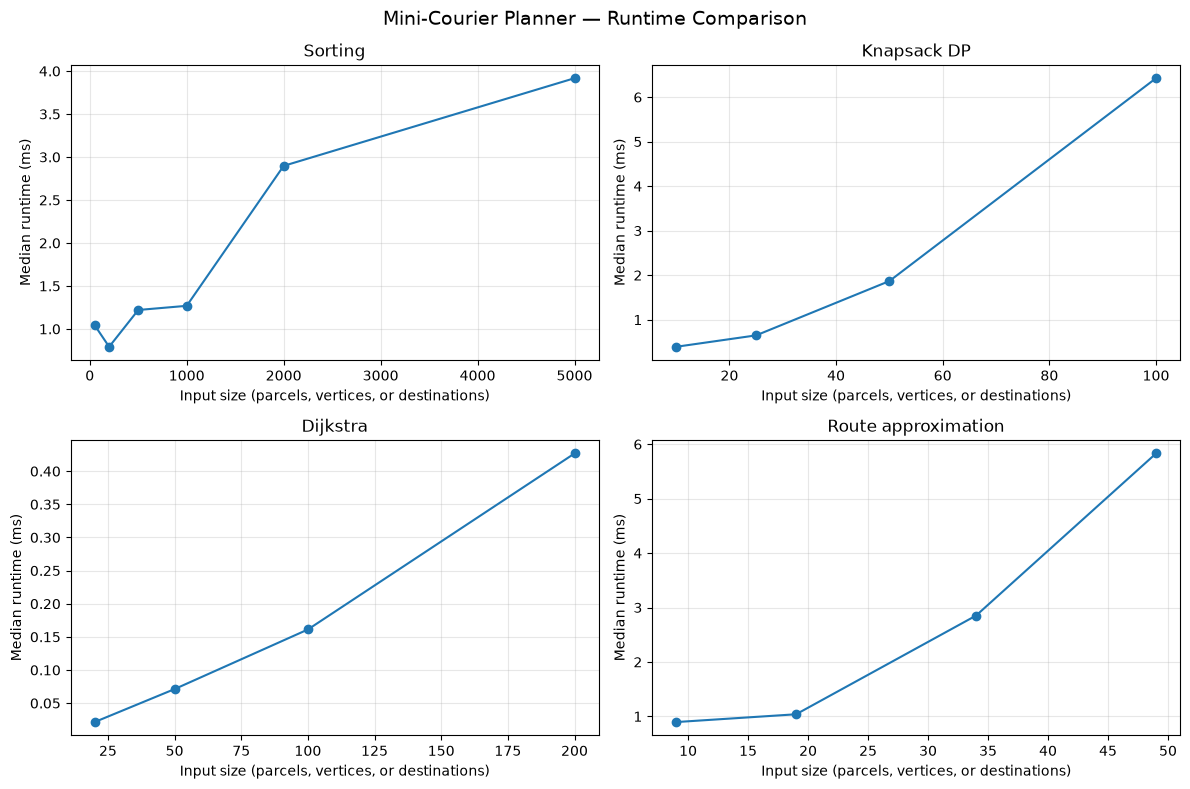

Saved runtime chart to: c:\Users\yadav\OneDrive\Desktop\mini-courier-planner\images\runtime_comparison.png

Interpretation:
- Sorting grows with parcel count, consistent with O(n log n) comparison sorting.
- Knapsack DP depends on both parcel count n and capacity W (O(nW)); its benchmark increases both.
- Dijkstra runtime depends on graph vertices and edges.
- Route approximation repeatedly computes shortest paths, so it is more expensive as destinations increase.
These are measurements from this run, not hardware-independent guarantees.


In [7]:
algorithm_order = ["Sorting", "Knapsack DP", "Dijkstra", "Route approximation"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for ax, algorithm in zip(axes, algorithm_order):
    subset = benchmark_results[benchmark_results["algorithm"] == algorithm].sort_values("input_size")
    ax.plot(subset["input_size"], subset["runtime_ms"], marker="o")
    ax.set_title(algorithm)
    ax.set_xlabel("Input size (parcels, vertices, or destinations)")
    ax.set_ylabel("Median runtime (ms)")
    ax.grid(True, alpha=0.3)
fig.suptitle("Mini-Courier Planner — Runtime Comparison", fontsize=14)
fig.tight_layout()
chart_path = IMAGE_DIR / "runtime_comparison.png"
fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved runtime chart to: {chart_path}")

print("\nInterpretation:")
print("- Sorting grows with parcel count, consistent with O(n log n) comparison sorting.")
print("- Knapsack DP depends on both parcel count n and capacity W (O(nW)); its benchmark increases both.")
print("- Dijkstra runtime depends on graph vertices and edges.")
print("- Route approximation repeatedly computes shortest paths, so it is more expensive as destinations increase.")
print("These are measurements from this run, not hardware-independent guarantees.")

## 7. Conclusion

The notebook combines the required algorithmic components into one courier-planning workflow. The packing output is optimal for the 0/1 Knapsack objective and configured capacity; each individual path is shortest under the road weights; the complete stop order uses a nearest-neighbor approximation and is not guaranteed to be the globally shortest tour. Runtime measurements and a chart are saved in the `images/` directory.